# Results — comparison of all models

Reads the per-wave scores saved by notebooks 02 and 03 (`results/*.csv`). All scores are on the test
wave of leave-one-wave-out cross-validation, averaged over the 21 waves.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd

from speed_dating.data import RESULTS_DIR, SPECIAL_WAVES, add_special_wave_flags, load_data
from speed_dating.evaluation import METRICS, evaluate, make_models, test_summary
from speed_dating.features import build_dataset

CONFIGS = {
    "Model 1: own profile → my decision": "model_own_profile",
    "Model 2: both profiles → my decision": "model_dec_both_profiles",
    "Model 2: profiles + ratings → my decision": "model_dec_profiles_and_ratings",
    "Model 3: both profiles → partner's decision": "model_dec_o_both_profiles",
    "Model 3: profiles + ratings → partner's decision": "model_dec_o_profiles_and_ratings",
}
results = pd.concat({name: pd.read_csv(RESULTS_DIR / f"{file}.csv") for name, file in CONFIGS.items()},
                    names=["config"]).reset_index(level=0)
test = results[results.split == "test"]
means = test.groupby(["config", "model", "metric"], sort=False).score.mean().unstack("metric")

## Summary
Best model of every configuration (by ROC AUC) next to the majority-class baseline.

In [2]:
rows = []
for config in CONFIGS:
    m = means.loc[config]
    best = m.drop("Majority baseline")["roc_auc"].idxmax()
    rows.append({"configuration": config,
                 "baseline accuracy": m.loc["Majority baseline", "accuracy"],
                 "best model": best,
                 "accuracy": m.loc[best, "accuracy"], "F1": m.loc[best, "f1"], "ROC AUC": m.loc[best, "roc_auc"]})
best_table = pd.DataFrame(rows).set_index("configuration")
best_table.round(3).to_csv(RESULTS_DIR / "summary.csv")
best_table.style.format({c: "{:.3f}" for c in best_table.columns if c != "best model"})

,baseline accuracy,best model,accuracy,F1,ROC AUC
configuration,,,,,
Model 1: own profile → my decision,0.560,Logistic Regression,0.581,0.428,0.596
Model 2: both profiles → my decision,0.562,Logistic Regression,0.600,0.487,0.629
Model 2: profiles + ratings → my decision,0.551,SVM (linear),0.769,0.740,0.845
Model 3: both profiles → partner's decision,0.562,Logistic Regression,0.600,0.487,0.629
Model 3: profiles + ratings → partner's decision,0.551,SVM (linear),0.771,0.742,0.845


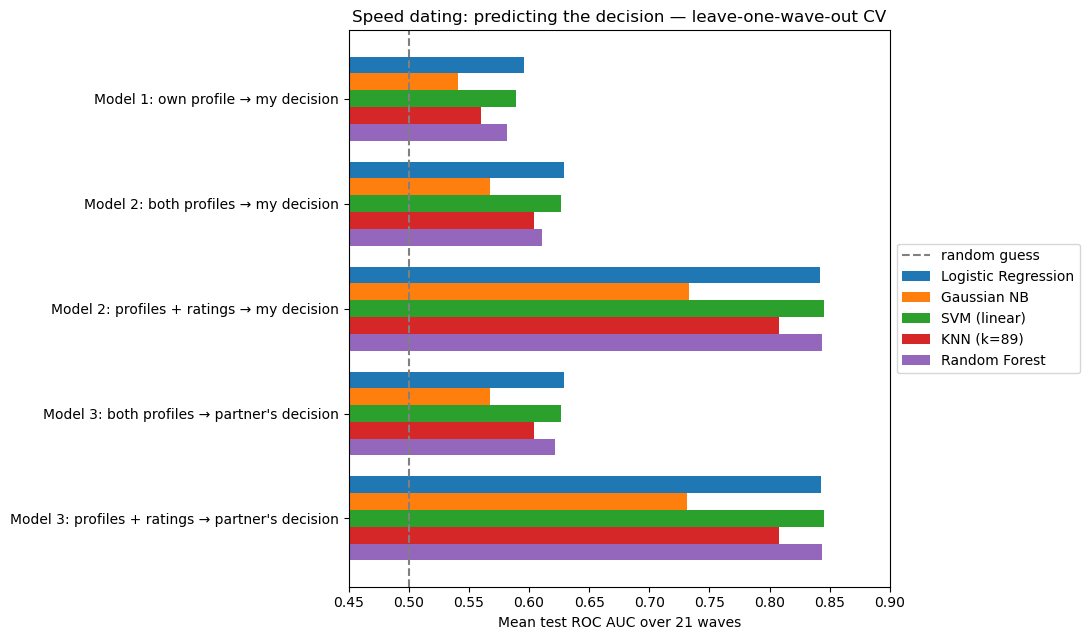

In [3]:
auc = means["roc_auc"].unstack("model").reindex(CONFIGS)
auc = auc.drop(columns="Majority baseline")
ax = auc.plot.barh(figsize=(11, 6.5), width=0.8)
ax.axvline(0.5, color="gray", ls="--", label="random guess")
ax.set_xlim(0.45, 0.9)
ax.set_xlabel("Mean test ROC AUC over 21 waves")
ax.set_ylabel("")
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Speed dating: predicting the decision — leave-one-wave-out CV")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=120)
plt.show()

* Without the scorecards (Model 1 and the "both profiles" sets) every model stays close to a random guess
  (ROC AUC 0.54–0.63).
* With the scorecards of the date, logistic regression, linear SVM and random forest reach ROC AUC 0.84.
* Gaussian Naive Bayes is the weakest model everywhere.

## Which waves are hard?
Test accuracy of the three best models (profiles + ratings → my decision), per wave, next to the size of
the wave and its share of "yes" decisions.

In [4]:
good = ["Logistic Regression", "SVM (linear)", "Random Forest"]
per_wave = (test[(test.config == "Model 2: profiles + ratings → my decision") & (test.metric == "accuracy")
                 & test.model.isin(good)].groupby("wave").score.mean().rename("accuracy"))
df = load_data()
X, y, waves = build_dataset(df, target="dec", feature_set="profiles_and_ratings")
wave_info = pd.DataFrame({"dates": waves.value_counts(), "share of yes": y.groupby(waves).mean()}).join(per_wave)
wave_info.sort_values("accuracy").head(6).style.format({"share of yes": "{:.1%}", "accuracy": "{:.3f}"})

,dates,share of yes,accuracy
wave,,,
1,118,62.7%,0.686
15,282,43.3%,0.720
3,128,35.2%,0.721
8,138,44.2%,0.725
18,50,48.0%,0.727
17,218,44.5%,0.729


In [5]:
print("correlation between wave accuracy and |share of yes − 50%|:",
      round(wave_info.accuracy.corr((wave_info["share of yes"] - 0.5).abs()), 2))

correlation between wave accuracy and |share of yes − 50%|: 0.03


* Test accuracy ranges from 69% to 86% between waves. The smallest waves (6, 16: 22 and 62 dates) are at
  both ends of the range — their score is mostly noise.
* The hardest wave, **wave 1**, is the only one where most decisions were "yes" (63%, against 42% overall):
  a model trained on the other, pickier events says "no" too often there.
* Apart from that, the difficulty of a wave is not explained by how balanced its decisions are
  (correlation 0.03).

## Special waves
Some events had a different set-up (dataset description):

In [6]:
special = add_special_wave_flags(df)
rows = []
for name, waves_list in SPECIAL_WAVES.items():
    inside = special[special[name] == 1]
    rows.append({"condition": name, "waves": waves_list, "dates": len(inside),
                 "share of yes": inside.dec.mean(), "match rate": inside.match.mean()})
others = special[special[list(SPECIAL_WAVES)].sum(axis=1) == 0]
rows.append({"condition": "all other waves", "waves": "", "dates": len(others),
             "share of yes": others.dec.mean(), "match rate": others.match.mean()})
pd.DataFrame(rows).set_index("condition").style.format({"share of yes": "{:.1%}", "match rate": "{:.1%}"})

,waves,dates,share of yes,match rate
condition,,,,
rated_1_10,"[6, 7, 8, 9]",1562,43.2%,16.4%
on_a_budget,[12],392,33.9%,10.7%
with_magazine,"[18, 21]",1040,37.5%,14.4%
with_book,"[19, 20]",534,45.5%,15.7%
all other waves,,4850,42.8%,17.5%


* **On a budget** (wave 12, "yes" to at most 50% of the partners): participants said "yes" to 34% of the
  partners instead of 43%, and the match rate fell from 17.5% to 10.7% — the limit made people choosier
  than required.
* **Magazine** waves have fewer "yes" decisions (37.5%); **book** waves and the waves with the 1–10
  preference scale do not differ from the rest.

Adding these conditions as features (as in the course version of the project):

In [7]:
X_flags = X.join(special.loc[X.index, list(SPECIAL_WAVES)])
models = {name: model for name, model in make_models().items() if name in ["Logistic Regression", "Random Forest"]}
with_flags = evaluate(X_flags, y, waves, models)
pd.concat({"without flags": test_summary(results[(results.config == "Model 2: profiles + ratings → my decision")
                                                 & results.model.isin(models)]),
           "with flags": test_summary(with_flags)}, axis=1)

without flags                 ...     with flags               
metric                    Accuracy             F1  ...             F1        ROC AUC
model                                              ...                              
Logistic Regression  0.764 ± 0.055  0.732 ± 0.075  ...  0.739 ± 0.080  0.844 ± 0.055
Random Forest        0.767 ± 0.046  0.731 ± 0.066  ...  0.730 ± 0.064  0.846 ± 0.043

[2 rows x 6 columns]

The flags change nothing — and in this evaluation they cannot: a condition that exists in one wave only
(`on_a_budget`, wave 12) is always 0 in the training waves when that wave is tested, so the model never
learns what it means. The effect of a condition is better read directly from the table above.

## Summary

* Stated preferences and self-descriptions hardly predict whether a person says "yes" — neither one's own
  nor the partner's: ROC AUC at most 0.63 before the date.
* After a four-minute date the decision is well predicted (77% accuracy, ROC AUC 0.84) from the two
  scorecards — mostly from "how much did I like the partner", attractiveness and "do I think the partner
  liked me".
* The course version of the project reported ~75% accuracy for Models 2 and 3. The corrected pipeline
  (preprocessing fitted inside every fold, only rows with missing values in the used features dropped)
  gives a similar 77% — now shown next to the 55% baseline, with F1 and ROC AUC.
* Models 2 and 3 are the same task on mirrored rows (every date is stored from both sides), so their
  results coincide.